# COCO-MLT diagnostics of the RTN skeleton: where AP is lost, and what RTN changes

Diagnoses the current skeleton version (`rtn_skeleton.py`), and compares it
with the previous version where that version's RTN runs are saved. It reads
the runs the three encoder notebooks saved and **trains nothing**; it uses
`rtn_skeleton.py` read-only, so the skeleton and its fingerprint stay
exactly as they are.

Version 1's diagnostics showed that RTN pushed down true positives that
also hold a look-alike (a related class seen together with them). Version 2
changes one component for that: a negative's relation counts only the
labels the anchor does not have. Step 5 shows whether the push-down is gone.

For every class, each test image without that class (a *negative*) is put
in one group by its strongest relation to the class: related and seen
together, related and never together, informative companion, generic
companion, seen together once, or unrelated. These are the skeleton's own
relation types (GloVe + WordNet).

**The questions**
1. Where is tail AP actually lost, and how much do RTN's targets cost?
   The answer is also the ceiling: the most AP RTN could ever win back.
2. How many test images are in each group?
3. Class by class: do classes whose confusion dropped more gain more AP?
4. Did RTN push down true positives that appear together with a look-alike?
   (this version, and the previous one if its runs are saved)
5. What does the anchor term change in training? (version 2 on)
6. For reference: the earlier RTN runs with relation types from CLIP's
   class-name text, against the CLIP-free skeleton, class by class.s

## Step 0: setup

In [1]:
import importlib
import os
import sys

from IPython.display import Image, display

HERE = os.path.dirname(globals().get("__vsc_ipynb_file__", "")) or os.path.abspath("")
PROJECT = next((p for p in (HERE, os.path.dirname(HERE))
                if os.path.isdir(os.path.join(p, "coco_mlt"))
                and os.path.exists(os.path.join(p, "relation_contrastive_runs.py"))), None)
if PROJECT is None:
    raise SystemExit("Put this notebook in the project folder (the one with coco_mlt/ and "
                     "relation_contrastive_runs.py) or in a folder inside it.")
places = [HERE, PROJECT] + sorted(os.path.join(PROJECT, d) for d in os.listdir(PROJECT)
                                  if os.path.isdir(os.path.join(PROJECT, d)))
found = {}
for name in ("rtn_skeleton.py", "rtn_diagnostics.py"):
    copies = sorted({os.path.join(p, name) for p in places
                     if os.path.exists(os.path.join(p, name))})
    if not copies:
        raise SystemExit(f"{name} not found next to this notebook or in the project folder.")
    if len({open(c, "rb").read() for c in copies}) > 1:
        raise SystemExit(f"There are different copies of {name}; keep only one:\n  "
                         + "\n  ".join(copies))
    found[name] = os.path.dirname(copies[0])
for p in [PROJECT] + sorted(set(found.values())):
    if p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)
os.chdir(PROJECT)

import rtn_skeleton as sk
import rtn_diagnostics as dg
importlib.reload(sk)
importlib.reload(dg)
print(f"Project folder: {PROJECT}\nSkeleton: {sk.__file__} (version {sk.SKELETON_VERSION})")

DATASET = dict(name="COCO-MLT", folder="coco_mlt",
               definitions=dict(file="coco_mlt/relations/coco_to_synset.json",
                                url=sk.COCO_WORDNET_URL))
ENCODERS = [
    dict(key="clip", label="CLIP ViT-B/16", features="coco_mlt/features"),
    dict(key="vit_b16", label="ViT-B/16 (ImageNet)",
         features="coco_mlt/encoders/vit_b_16_224/features"),
    dict(key="resnet50", label="ResNet-50 (ImageNet, input 448)",
         features="coco_mlt/encoders/resnet50_448/features"),
]
QUICK_TEST = False      # True only to test this notebook on the tiny test runs
OUT = dg.output_folder(DATASET["folder"])
os.makedirs(OUT, exist_ok=True)

Project folder: c:\Users\Admin\Documents\MSc-Project---RTN
Skeleton: c:\Users\Admin\Documents\MSc-Project---RTN\RTN2\rtn_skeleton.py (version 2)


## Step 1: load the saved runs

The fingerprints must match the ones in the saved results, so these are
exactly the runs behind this version's tables. The previous version's RTN
runs are loaded too, if they are saved (same split, same MulSupCon runs).

In [2]:
diags = dg.load(DATASET, ENCODERS, quick_test=QUICK_TEST)

COCO-MLT, CLIP ViT-B/16: skeleton version 2; results in c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\clip\v2
GloVe words not found (ignored): {'baseball glove': ['handwear'], 'donut': ['friedcake']}
Related classes (top 5% most similar names) of the tail classes and of names with several meanings:
Training images: 1516 for training, 393 for the dev set; test images: 5000. Skeleton fingerprint: ff0a7b1cf907. Relation pairs (training part):
Computed in 1 s. Average gap per relation type (AUC points, minus the baseline group; lower is better):
Change in the gap, RTN vs MulSupCon (95% interval; below 0 = less confusion):
COCO-MLT, ViT-B/16 (ImageNet): skeleton version 2; results in c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\vit_b16\v2
GloVe words not found (ignored): {'baseball glove': ['handwear'], 'donut': ['friedcake']}
Related classes (top 5% most similar names) of the tail classes and of names with several meanings:
Training images: 1516 for t

,encoder,skeleton_version,fingerprint,matches_saved_results,previous_version_runs,earlier_clip_text_runs
0,CLIP ViT-B/16,2,ff0a7b1cf907,True,saved,"round 6, alpha 4"
1,ViT-B/16 (ImageNet),2,ff0a7b1cf907,True,saved,-
2,"ResNet-50 (ImageNet, input 448)",2,ff0a7b1cf907,True,saved,"round 7, alpha 1"


## Step 2: where is AP lost?

For each class: how much its AP rises if one group of negatives is taken
out of the ranking, which is exactly the AP those negatives cost (AP
points, averaged over the classes of a cohort and the 3 seeds). The last
column takes out all of RTN's targets together (related seen together,
related never together, informative companions): **the most AP RTN could
ever win back** on that cohort. The groups overlap in their effect, so the
columns do not add up to 100 - AP. Rows for the previous version (if saved)
show what the change of component did.

How to read it: if RTN's targets cost little AP compared with the other
groups, the ceiling is low and RTN needs to target other mistakes. If they
cost a lot and RTN barely reduced that cost, RTN is too gentle.

In [3]:
lost = dg.where_ap_is_lost(diags)
lost

,encoder,cohort,variant,AP,"related, seen together","related, never together",informative companion,generic companion,seen together once,unrelated,all RTN targets together
0,CLIP ViT-B/16,tail,MulSupCon,64.27,3.95,1.28,1.05,2.07,0.28,1.22,6.66
1,CLIP ViT-B/16,tail,RTN v2,64.38,3.83,1.15,0.98,1.99,0.18,1.39,6.29
2,CLIP ViT-B/16,tail,RTN v1,64.71,4.08,1.02,1.04,2.19,0.18,1.32,6.51
3,CLIP ViT-B/16,medium,MulSupCon,67.99,6.44,0.30,1.60,2.44,0.25,0.75,9.83
4,CLIP ViT-B/16,medium,RTN v2,67.57,6.11,0.28,1.62,2.32,0.26,0.86,9.40
5,CLIP ViT-B/16,medium,RTN v1,67.53,6.20,0.30,1.56,2.53,0.26,0.78,9.47
6,CLIP ViT-B/16,head,MulSupCon,54.04,11.93,0.00,5.79,4.31,0.11,0.39,22.11
7,CLIP ViT-B/16,head,RTN v2,53.70,11.76,0.00,5.61,4.40,0.11,0.45,21.57
8,CLIP ViT-B/16,head,RTN v1,53.66,11.67,0.00,5.65,4.53,0.11,0.42,21.43
9,ViT-B/16 (ImageNet),tail,MulSupCon,54.15,3.74,1.13,1.17,2.06,0.22,2.46,6.46


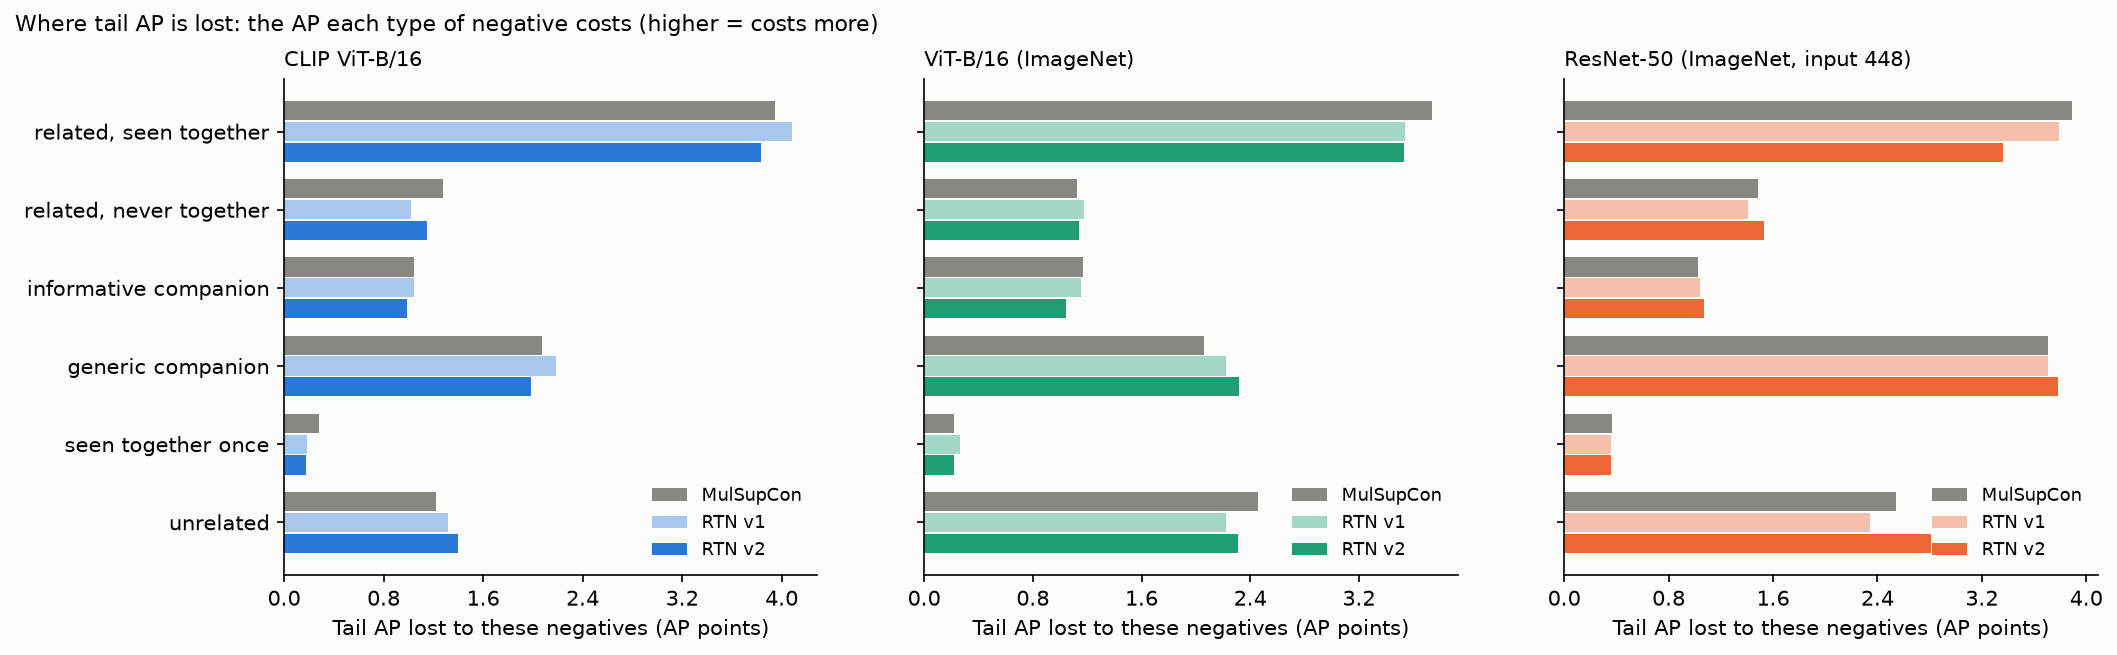

In [4]:
fig1 = os.path.join(OUT, "where_tail_ap_is_lost.png")
dg.figure_lost(diags, fig1)
display(Image(filename=fig1))

## Step 3: how many test images are in each group?

Average number of test negatives per class in each group, and of test
positives. A group with few images cannot cost much AP, however confusable
it is.

In [5]:
counts = dg.counts_table(diags)
counts

,encoder,cohort,positives,"related, seen together","related, never together",informative companion,generic companion,seen together once,unrelated
0,CLIP ViT-B/16,tail,79.5,178.8,317.3,341.6,2308.4,238.5,1536.0
1,CLIP ViT-B/16,medium,136.4,448.2,127.5,401.4,2542.8,285.7,1057.9
2,CLIP ViT-B/16,head,370.1,657.2,19.6,459.1,2713.3,167.6,613.2
3,ViT-B/16 (ImageNet),tail,79.5,178.8,317.3,341.6,2308.4,238.5,1536.0
4,ViT-B/16 (ImageNet),medium,136.4,448.2,127.5,401.4,2542.8,285.7,1057.9
5,ViT-B/16 (ImageNet),head,370.1,657.2,19.6,459.1,2713.3,167.6,613.2
6,"ResNet-50 (ImageNet, input 448)",tail,79.5,178.8,317.3,341.6,2308.4,238.5,1536.0
7,"ResNet-50 (ImageNet, input 448)",medium,136.4,448.2,127.5,401.4,2542.8,285.7,1057.9
8,"ResNet-50 (ImageNet, input 448)",head,370.1,657.2,19.6,459.1,2713.3,167.6,613.2


## Step 4: class by class, does less confusion go with more AP?

For the tail classes: the change in the skeleton's related-class gap
(Control 1) and in the AP lost to RTN's targets, against the change in AP.
A strongly *negative* Spearman correlation would mean that classes whose
confusion dropped more did gain more AP; a correlation near zero means the
confusion RTN removed is not what decides their AP.

,encoder,tail classes,Spearman: gap change vs AP change,Spearman: change in AP lost to targets vs AP change
0,CLIP ViT-B/16,25,0.06,-0.59
1,ViT-B/16 (ImageNet),25,-0.16,0.18
2,"ResNet-50 (ImageNet, input 448)",25,-0.36,-0.39
3,all three,75,-0.13,-0.29


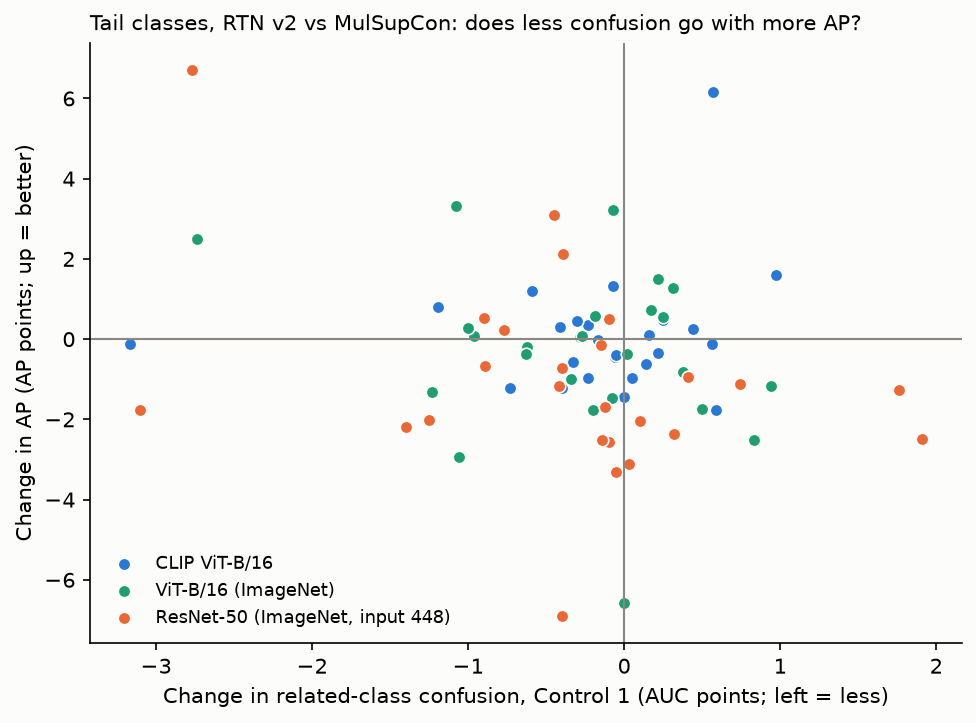

,encoder,class,test positives,AP change,"gap change, C1",change in AP lost to RTN targets
24,CLIP ViT-B/16,toothbrush,34,-1.77,0.59,0.98
14,CLIP ViT-B/16,skis,120,-1.44,0.00,0.71
22,CLIP ViT-B/16,scissors,28,-1.23,-0.40,-0.26
4,CLIP ViT-B/16,parking meter,37,-1.21,-0.73,3.32
7,CLIP ViT-B/16,sheep,65,-0.98,0.05,-0.25
...,...,...,...,...,...,...
45,ViT-B/16 (ImageNet),donut,62,1.28,0.31,0.51
43,ViT-B/16 (ImageNet),surfboard,149,1.50,0.22,0.06
28,ViT-B/16 (ImageNet),stop sign,69,2.50,-2.74,-1.22
38,ViT-B/16 (ImageNet),frisbee,84,3.21,-0.07,0.86


In [6]:
corr, per_class = dg.class_by_class(diags)
display(corr)
fig2 = os.path.join(OUT, "tail_classes_confusion_vs_ap.png")
dg.figure_classes(per_class, diags, fig2)
display(Image(filename=fig2))
per_class.sort_values(["encoder", "AP change"])

## Step 5: did RTN push down true positives?

For each class, its test positives are split into those that also hold a
related class seen together with it (a look-alike in the same image) and
the others. The table shows the change, RTN minus MulSupCon, in the share
of negatives each positive outranks (percentage points, 95% interval over
classes). Below zero means RTN pushed those positives down. With version 1
this was below zero for positives with a look-alike in most cohorts; if the
anchor term works, version 2's change is about zero or above.

In [7]:
pos = dg.positives(diags)
pos

,encoder,cohort,positives with a look-alike: classes,"positives with a look-alike: change, RTN v2","positives with a look-alike: change, RTN v1",positives without: classes,"positives without: change, RTN v2","positives without: change, RTN v1"
0,CLIP ViT-B/16,tail,16,"+0.72 [-0.66, +2.69]","+0.79 [-0.32, +2.29]",25,"-0.06 [-0.29, +0.18]","+0.01 [-0.33, +0.40]"
1,CLIP ViT-B/16,medium,32,"-0.50 [-0.94, +0.01]","-0.51 [-0.80, -0.23]",33,"+0.07 [-0.38, +0.61]","+0.03 [-0.28, +0.40]"
2,CLIP ViT-B/16,head,22,"-0.50 [-0.80, -0.25]","-0.71 [-1.00, -0.49]",22,"-0.43 [-0.70, -0.18]","-0.37 [-0.56, -0.17]"
3,ViT-B/16 (ImageNet),tail,16,"-0.17 [-1.60, +1.53]","-1.51 [-2.93, -0.33]",25,"+0.05 [-0.36, +0.43]","-0.00 [-0.36, +0.36]"
4,ViT-B/16 (ImageNet),medium,32,"-0.82 [-1.41, -0.27]","-0.27 [-0.76, +0.29]",33,"-0.46 [-0.72, -0.20]","+0.02 [-0.30, +0.36]"
5,ViT-B/16 (ImageNet),head,22,"-0.46 [-0.74, -0.19]","-0.19 [-0.41, +0.03]",22,"-0.48 [-0.73, -0.23]","+0.07 [-0.20, +0.33]"
6,"ResNet-50 (ImageNet, input 448)",tail,16,"-1.11 [-2.64, +0.43]","-1.54 [-3.12, +0.05]",25,"-0.03 [-0.70, +0.66]","-0.26 [-0.63, +0.08]"
7,"ResNet-50 (ImageNet, input 448)",medium,32,"-0.15 [-0.54, +0.24]","-0.41 [-0.83, -0.00]",33,"+0.25 [-0.16, +0.74]","+0.07 [-0.30, +0.43]"
8,"ResNet-50 (ImageNet, input 448)",head,22,"-0.27 [-0.46, -0.06]","-0.25 [-0.44, -0.05]",22,"-0.41 [-0.80, -0.07]","-0.22 [-0.55, +0.08]"


## Step 6: what the anchor term changes in training

On the training part's labels (the same for every encoder): of the
(anchor, negative) pairs that version 1 gives extra weight, the share whose
look-alike the anchor also has. From version 2 on, those pairs lose that
extra weight, because the shared label explains why the negative looks like
the anchor. "Related, never together" is always 0%: an anchor with the
class never has such a look-alike.

In [8]:
anchor = dg.anchor_term(diags)
anchor

,cohort,relation type,"(anchor, negative) pairs with extra weight in v1",anchor also has the look-alike (%)
0,tail,"related, seen together",17011,35.7
1,tail,"related, never together",17301,0.0
2,tail,informative companion,41730,43.8
3,medium,"related, seen together",333451,37.2
4,medium,"related, never together",41649,0.0
5,medium,informative companion,316440,35.5
6,head,"related, seen together",1721453,32.2
7,head,"related, never together",16865,0.0
8,head,informative companion,630048,27.0


## Step 7: for reference, earlier relation types vs GloVe + WordNet

Rounds 6 and 7 trained RTN with relation types from CLIP's class-name text
(CLIP: alpha 4; ResNet-50: alpha 1). Against the same MulSupCon runs, this
compares their tail AP change with this skeleton version's, class by
class, and lists the tail classes where the earlier runs did best relative
to the new ones, with their GloVe + WordNet related classes. It uses only
the scores those runs saved (no CLIP model) and does not change the
skeleton; it shows whether the relation source explains part of the gap.

In [9]:
early_summary, early_classes = dg.earlier_relations(diags)
display(early_summary)
early_classes

,encoder,earlier runs,"tail AP change, earlier relation types","tail AP change, skeleton v2",Spearman over tail classes
0,CLIP ViT-B/16,"round 6, alpha 4",0.42,0.11,-0.1
1,"ResNet-50 (ImageNet, input 448)","round 7, alpha 1",0.82,-1.03,0.0


,encoder,class,"AP change, earlier","AP change, skeleton v2",GloVe + WordNet related classes
0,CLIP ViT-B/16,toothbrush,3.30,-1.77,"knife, laptop, scissors, hair drier"
1,CLIP ViT-B/16,snowboard,5.80,1.20,"bicycle, skis, skateboard, surfboard"
2,CLIP ViT-B/16,parking meter,2.80,-1.21,"bicycle, car, bus, traffic light"
3,CLIP ViT-B/16,skis,2.17,-1.44,"bicycle, motorcycle, snowboard, skateboard"
4,CLIP ViT-B/16,scissors,0.25,-1.23,"backpack, knife, spoon, toothbrush"
5,CLIP ViT-B/16,train,0.93,-0.45,"car, bus, truck, traffic light"
6,"ResNet-50 (ImageNet, input 448)",parking meter,10.64,-1.28,"bicycle, car, bus, traffic light"
7,"ResNet-50 (ImageNet, input 448)",bear,7.10,-2.36,"dog, sheep, giraffe, teddy bear"
8,"ResNet-50 (ImageNet, input 448)",sheep,1.38,-6.90,"dog, cow, elephant, bear"
9,"ResNet-50 (ImageNet, input 448)",kite,3.78,-3.30,"airplane, tie, bed, hair drier"


## Step 8: save

In [10]:
for name, table in (("where_ap_is_lost", lost), ("negatives_per_group", counts),
                    ("class_correlations", corr), ("tail_classes", per_class),
                    ("positives", pos), ("anchor_term", anchor),
                    ("earlier_relations", early_summary),
                    ("earlier_relations_classes", early_classes)):
    table.to_csv(os.path.join(OUT, f"{name}.csv"), index=False)
print(f"Saved the tables and figures to {os.path.abspath(OUT)}")

Saved the tables and figures to c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\diagnostics\v2
